<img src="https://www.th-koeln.de/img/logo.svg" style="float:right;" width="200">

# 4th exercise: <font color="#C70039">Use Isolation Forest for anomaly detection</font>
* Course: AML
* Lecturer: <a href="https://www.gernotheisenberg.de/">Gernot Heisenberg</a>
* Author of notebook: <b>Yara Dinesh Kumar</b>
* Matriculation number: <b>11701170</b>
* Date:   18.11.2026

<img src="https://upload.wikimedia.org/wikipedia/commons/c/ce/Isolating_a_Non-Anomalous_Point.png" style="float: center;" width="450">

---------------------------------
**GENERAL NOTE 1**:
Please make sure you are reading the entire notebook, since it contains a lot of information on your tasks (e.g. regarding the set of certain parameters or a specific computational trick), and the written mark downs as well as comments contain a lot of information on how things work together as a whole.

**GENERAL NOTE 2**:
* Please, when commenting source code, just use English language only.
* When describing an observation please use English language, too
* This applies to all exercises throughout this course.  

---------------------

### <font color="ce33ff">DESCRIPTION</font>:
This notebook allows you for using the Isolation Forest algorithm for anomaly detection. Isolation Forest is an unsupervised learning algorithm that belongs to the ensemble decision trees family. The following <a href="https://cs.nju.edu.cn/zhouzh/zhouzh.files/publication/icdm08b.pdf">paper</a> explains the details on its theory and implementation.

-------------------------------------------------------------------------------------------------------------

### <font color="FFC300">TASKS</font>:
The tasks that you need to work on within this notebook are always indicated below as bullet points.
If a task is more challenging and consists of several steps, this is indicated as well.
Make sure you have worked down the task list and commented your doings.
This should be done by using markdown.<br>
<font color=red>Make sure you don't forget to specify your name and your matriculation number in the notebook.</font>

**YOUR TASKS in this exercise are as follows**:
1. import the notebook to Google Colab or use your local machine.
2. make sure you specified your name and your matriculation number in the header below my name and date.
    * set the date too and remove mine.
3. read the entire notebook carefully
    * add comments wherever you feel it necessary for better understanding
    * run the notebook for the first time.

4. take the three data sets from exercise 1 and apply the isolation forest to them.
5. implement an appropriate visualisation (chart) that renders the result (anomaly={yes,no}) for every data point TOGETHER with the original data point in your data set.
-----------------------------------------------------------------------------------

### First example

In [7]:
# Google Colab setup: make repository files available under the expected relative paths.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repository = "/content/AML"
    if not os.path.isdir(repository):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/gheisenberg/AML.git", repository], check=True)
    os.chdir(repository)

In [8]:
# Import the Isolation Forest estimator and create a reproducible two-feature data set.
# Each row of random_data is one observation that the model can isolate.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest

rng = np.random.default_rng(1)
random_data = rng.normal(loc=20.0, scale=20.0, size=(50_000, 2))

This code will output the predictions for each data point in an array. If the result is -1, it means that this specific data point is an outlier. If the result is 1, then it means that the data point is not an outlier.

In [9]:
# fit_predict trains the forest and immediately returns one label per observation.
# A label of -1 means outlier; a label of 1 means inlier.
# Fit the estimator and return one label per training observation.
isolation_forest_1 = IsolationForest(
    max_samples=100,
    contamination="auto",
    random_state=1,
    n_jobs=-1,
)
outlier_labels = isolation_forest_1.fit_predict(random_data)

print(outlier_labels[:200])
print(f"Detected outliers: {np.count_nonzero(outlier_labels == -1)}")

[ 1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1 -1 -1  1 -1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1 -1  1  1  1  1  1  1 -1  1  1  1  1  1 -1
  1  1  1  1  1 -1 -1  1  1  1  1  1 -1 -1 -1  1  1  1  1  1  1  1 -1  1
  1  1  1  1  1 -1  1 -1  1  1  1 -1  1  1  1 -1  1  1  1 -1  1  1  1  1
 -1  1  1  1 -1  1  1 -1  1  1  1  1  1  1  1  1  1  1  1  1 -1  1  1  1
  1  1 -1  1  1  1  1  1  1  1  1 -1  1  1  1  1 -1  1  1 -1  1  1  1  1
  1  1  1  1  1 -1  1  1  1  1  1 -1  1  1  1 -1  1  1  1  1  1  1  1  1
 -1 -1  1  1  1  1  1 -1  1  1  1  1  1  1  1  1  1 -1  1 -1  1  1  1  1
  1  1  1  1  1 -1  1  1]
Detected outliers: 13560


### Second example

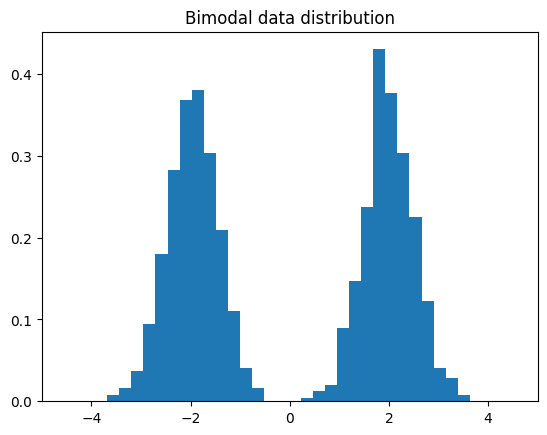

In [10]:
# Build two dense groups so low-density regions are easy to interpret visually.
# The following histogram is the reference distribution for the anomaly model.
# Create and visualize a bimodal data distribution.
bimodal_data = np.concatenate(
    (
        rng.normal(loc=-2.0, scale=0.5, size=500),
        rng.normal(loc=2.0, scale=0.5, size=500),
    )
)

plt.hist(bimodal_data, bins=30, density=True)
plt.xlim(-5, 5)
plt.title("Bimodal data distribution")
plt.show()

Note, that there are three regions where the data has low probability to appear:
* one on the right side of the distribution
* another one on the left
* and another around zero.

Let's see if the IsolationForest is able to identify these three regions

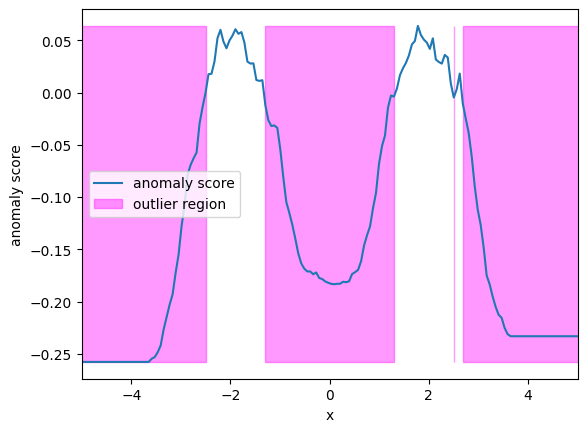

In [11]:
# Evaluate anomaly scores on a regular grid instead of only on training points.
# This makes the predicted outlier regions visible on the plot.
# Fit a reproducible Isolation Forest with 100 estimators.
isolation_forest_2 = IsolationForest(n_estimators=100, random_state=1)
isolation_forest_2.fit(bimodal_data.reshape(-1, 1))

# Evaluate the anomaly score over a regular grid on the x-axis.
score_grid = np.linspace(-6, 6, 200).reshape(-1, 1)
anomaly_score = isolation_forest_2.decision_function(score_grid)
outlier_labels = isolation_forest_2.predict(score_grid)

plt.plot(score_grid[:, 0], anomaly_score, label="anomaly score")
plt.fill_between(
    score_grid[:, 0],
    anomaly_score.min(),
    anomaly_score.max(),
    where=outlier_labels == -1,
    color="#FF00FF",
    alpha=0.4,
    label="outlier region",
)
plt.legend()
plt.ylabel("anomaly score")
plt.xlabel("x")
plt.xlim(-5, 5)
plt.show()

## Exercise Solutions: Isolation Forest on Real-World Datasets
### Tasks 5 & 6: Applying Isolation Forest and Visualizing Every Observation (`anomaly = {yes, no}`)
The same three Kaggle datasets from Exercise 1, fit an `IsolationForest` (`n_estimators=100`, `contamination="auto"`, `random_state=1`) on each dataset, and plot every data point alongside its binary classification (`anomaly = no` vs. `anomaly = yes`).

Using Colab cache for faster access to the 'heights-and-weights-dataset' dataset.
Using Colab cache for faster access to the 'student-performance-dataset' dataset.
Using Colab cache for faster access to the 'california-housing-prices' dataset.
=== Normal 1: Human Height (Inches) ===
Total points: 25000
anomaly = no  (inliers, label=1)  : 19496
anomaly = yes (outliers, label=-1): 5504 (22.02%)

=== Normal 2: Weekly Self-Study Hours ===
Total points: 1000000
anomaly = no  (inliers, label=1)  : 737343
anomaly = yes (outliers, label=-1): 262657 (26.27%)

=== Non-Normal: CA Median Income ($10k) ===
Total points: 20640
anomaly = no  (inliers, label=1)  : 17077
anomaly = yes (outliers, label=-1): 3563 (17.26%)



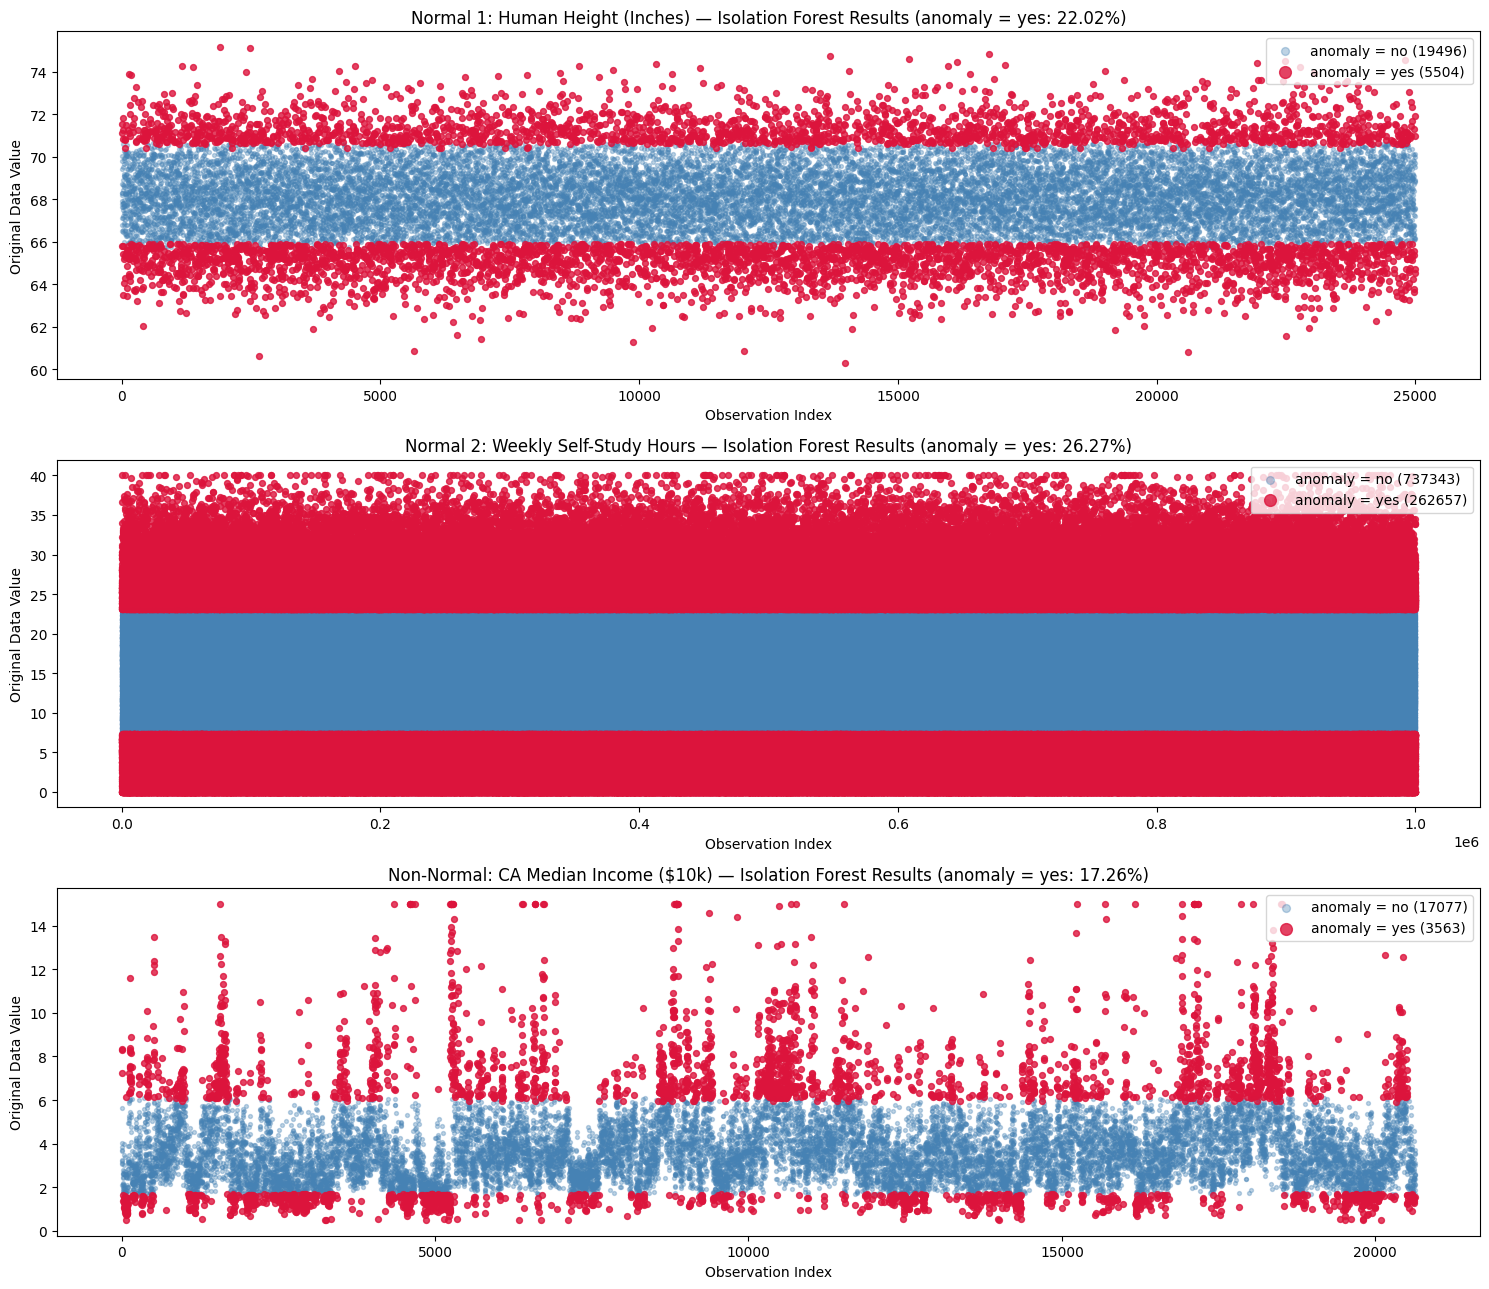

In [12]:
import glob
import os
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import userdata
from sklearn.ensemble import IsolationForest

# Load Kaggle API token securely from Colab Secrets
os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

# 1. Normal Dataset 1: Human Heights (Inches)
path_1 = kagglehub.dataset_download("burnoutminer/heights-and-weights-dataset")
df_1 = pd.read_csv(glob.glob(os.path.join(path_1, "*.csv"))[0])
data_normal_1 = df_1["Height(Inches)"].dropna().to_numpy()

# 2. Normal Dataset 2: Student Weekly Self-Study Hours
path_2 = kagglehub.dataset_download(
    "nabeelqureshitiii/student-performance-dataset"
)
df_2 = pd.read_csv(glob.glob(os.path.join(path_2, "*.csv"))[0])
data_normal_2 = df_2["weekly_self_study_hours"].dropna().to_numpy()

# 3. Non-Normal Dataset: California Median Income (right-skewed)
path_3 = kagglehub.dataset_download("camnugent/california-housing-prices")
df_3 = pd.read_csv(glob.glob(os.path.join(path_3, "*.csv"))[0])
data_non_normal = df_3["median_income"].dropna().to_numpy()

datasets = {
    "Normal 1: Human Height (Inches)": data_normal_1,
    "Normal 2: Weekly Self-Study Hours": data_normal_2,
    "Non-Normal: CA Median Income ($10k)": data_non_normal,
}

# Task 5 & 6: Fit Isolation Forest and render every data point with anomaly={yes, no}
fig, axes = plt.subplots(3, 1, figsize=(15, 13))

for ax, (name, values) in zip(axes, datasets.items()):
    # Reshape 1D array to 2D column vector (n_samples, 1) as required by scikit-learn
    X = values.reshape(-1, 1)

    # Fit Isolation Forest and predict labels: 1 -> inlier (no), -1 -> outlier (yes)
    iso_forest = IsolationForest(
        n_estimators=100,
        contamination="auto",
        random_state=1,
        n_jobs=-1,
    )
    preds = iso_forest.fit_predict(X)
    scores = iso_forest.decision_function(X)

    # Map predictions to boolean mask for anomaly={yes, no}
    is_anomaly = preds == -1
    n_anom = np.count_nonzero(is_anomaly)
    pct_anom = (n_anom / values.size) * 100

    print(f"=== {name} ===")
    print(f"Total points: {values.size}")
    print(f"anomaly = no  (inliers, label=1)  : {values.size - n_anom}")
    print(
        f"anomaly = yes (outliers, label=-1): {n_anom} ({pct_anom:.2f}%)\n"
    )

    indices = np.arange(values.size)

    # Render every data point together with its original value and anomaly={yes, no} label
    ax.scatter(
        indices[~is_anomaly],
        values[~is_anomaly],
        color="steelblue",
        alpha=0.35,
        s=8,
        label=f"anomaly = no ({values.size - n_anom})",
    )
    ax.scatter(
        indices[is_anomaly],
        values[is_anomaly],
        color="crimson",
        alpha=0.8,
        s=18,
        zorder=5,
        label=f"anomaly = yes ({n_anom})",
    )

    ax.set_title(
        f"{name} — Isolation Forest Results (anomaly = yes: {pct_anom:.2f}%)"
    )
    ax.set_xlabel("Observation Index")
    ax.set_ylabel("Original Data Value")
    ax.legend(loc="upper right", markerscale=2)

plt.tight_layout()
plt.show()

### Observations & Interpretation of Isolation Forest Results

1. **Effect of `contamination="auto"` vs. Statistical Thresholds (`3σ` / `IQR`):**
   * With `contamination="auto"`, scikit-learn classifies every observation with a negative `decision_function` score (`< 0`) as `anomaly = yes` (`label = -1`), using a default subsample size of `max_samples = 256` per tree.
   * Because random axis-aligned splits isolate points outside the dense central core much sooner than deep interior points, `contamination="auto"` flags a broad outer band (`17.26%` to `26.27%`) across all three datasets—significantly more than the `~0.2%–0.3%` flagged by the 3-sigma rule in Exercise 1 or `~0.35%–3.30%` by Boxplots in Exercise 2[cite: 4, 7, 9, 10]. (If fewer, stricter outliers are desired in practice, `contamination` can be set explicitly, e.g., `contamination=0.01`.)

2. **Normal Dataset 1 : Human Height (`5,504 / 25,000` anomalies = `22.02%`):**
   * Isolation Forest keeps the dense central core (`~66.0` to `~70.3` inches, `19,496` points) as `anomaly = no` and symmetrically labels both the lower band (`< 66.0` inches) and upper band (`> 70.3` inches) as `anomaly = yes`[cite: 9].

3. **Normal Dataset 2 : Weekly Self-Study Hours (`262,657 / 1,000,000` anomalies = `26.27%`):**
   * The central bulk (`~7.8` to `~22.8` hours, `737,343` points) is classified as `anomaly = no`, while both low-study-hour observations (`< 7.8` hours, including the `0`-hour spike) and high-study-hour observations (`> 22.8` hours) are classified as `anomaly = yes`[cite: 9, 10].

4. **Non-Normal Dataset : California Median Income (`3,563 / 20,640` anomalies = `17.26%`):**
   * Unlike Exercise 1 (`3σ`) and Exercise 2 (`Boxplot`), which missed all low-income outliers because their lower fences went below zero[cite: 4, 7], Isolation Forest successfully detects outliers on **both** sides of the skewed distribution: very low-income tracts (`< ~1.8`, i.e., under `$18k`) as well as high-income tracts (`> ~6.0`, i.e., over `$60k`) are flagged as `anomaly = yes`, while the dense middle-income band (`~1.8–6.0`, `17,077` points) is kept as `anomaly = no`[cite: 9, 10].